In [ ]:
import os
import re
import unicodedata
import zipfile
import numpy as np
import pandas as pd

pasta_arr = "/content/dados_arrecadacao"
pasta_exec = "/content/dados_execucao"


def normalizar_nome_coluna(col: str) -> str:
  col = str(col).strip().lstrip("\ufeff")
  col = (
      unicodedata.normalize("NFKD", col)
      .encode("ascii", "ignore")
      .decode("utf-8")
  )
  return re.sub(r"[^a-zA-Z0-9]+", "_", col.lower()).strip("_")


def limpar_numero_br(serie: pd.Series) -> pd.Series:
  if pd.api.types.is_numeric_dtype(serie):
    return serie.astype(float)
  s = (
      serie.astype(str)
      .str.replace("R$", "", regex=False)
      .str.replace(r"\s+", "", regex=True)
      .str.replace(".", "", regex=False)
      .str.replace(",", ".", regex=False)
  )
  return pd.to_numeric(s, errors="coerce")

#def ler_csv_resiliente: Testa combinações de codificação e separador até o arquivo ser lido corretamente
#Isso evita erro com CSVs de origens diferentes.


def ler_csv_resiliente(caminho: str) -> pd.DataFrame:
  for enc in ["utf-8-sig", "latin1", "cp1252"]:
    for sep in [";", ","]:
      try:
        df = pd.read_csv(caminho, encoding=enc, sep=sep, low_memory=False)
        if df.shape[1] > 1:
          df.columns = [normalizar_nome_coluna(c) for c in df.columns]
          return df
      except Exception:
        continue
  raise ValueError(f"Erro ao ler: {caminho}")

#extrair_competencia: Descobre ano e mês de cada linha, primeiro pelas colunas do arquivo e, se não achar,
#pelo nome do arquivo.
#Filtra 2021 a 2025 e cria a chave ano_mes (ex.: 2023-05), que será usada para cruzar as bases.


def extrair_competencia(df: pd.DataFrame, nome_arquivo: str) -> pd.DataFrame:
  df = df.copy()
  meses_pt = {
      "jan": 1,
      "janeiro": 1,
      "fev": 2,
      "fevereiro": 2,
      "mar": 3,
      "marco": 3,
      "abr": 4,
      "abril": 4,
      "mai": 5,
      "maio": 5,
      "jun": 6,
      "junho": 6,
      "jul": 7,
      "julho": 7,
      "ago": 8,
      "agosto": 8,
      "set": 9,
      "setembro": 9,
      "out": 10,
      "outubro": 10,
      "nov": 11,
      "novembro": 11,
      "dez": 12,
      "dezembro": 12,
  }

  match_ym = re.search(r"(20\d{2})[-_]?(0[1-9]|1[0-2])", nome_arquivo)
  match_y = re.search(r"(20\d{2})", nome_arquivo)

  col_ano = next(
      (
          c
          for c in df.columns
          if c
          in (
              "ano",
              "exercicio",
              "ano_exercicio",
              "ano_arrecadacao",
              "ano_lancamento",
          )
      ),
      None,
  )
  col_mes = next(
      (
          c
          for c in df.columns
          if c
          in (
              "mes",
              "cod_mes",
              "codigo_mes",
              "num_mes",
              "mes_arrecadacao",
              "mes_lancamento",
          )
      ),
      None,
  )

  if col_ano:
    df["ano"] = pd.to_numeric(df[col_ano], errors="coerce")
  elif match_ym:
    df["ano"] = int(match_ym.group(1))
  elif match_y:
    df["ano"] = int(match_y.group(1))
  else:
    df["ano"] = np.nan

  if col_mes:
    s_mes = df[col_mes].astype(str).str.strip().str.lower()
    df["mes"] = pd.to_numeric(s_mes, errors="coerce").fillna(
        s_mes.map(meses_pt)
    )
  elif match_ym:
    df["mes"] = int(match_ym.group(2))
  else:
    df["mes"] = np.nan

  df = df.dropna(subset=["ano", "mes"]).copy()
  df["ano"] = df["ano"].astype(int)
  df["mes"] = df["mes"].astype(int)
  df = df[df["ano"].between(2021, 2025)]
  df = df[df["mes"].between(1, 12)]
  df["ano_mes"] = (
      df["ano"].astype(str) + "-" + df["mes"].astype(str).str.zfill(2)
  )
  return df

#def listar_csvs_pasta: Extrai os .zip, ignora arquivos inválidos (HTML),
#lê cada CSV com as funções acima e concatena tudo em uma única tabela, sem duplicatas.


def listar_csvs_pasta(pasta: str) -> list:
  pasta_ext = os.path.join(pasta, "extraidos")
  os.makedirs(pasta_ext, exist_ok=True)
  for item in sorted(os.listdir(pasta)):
    caminho = os.path.join(pasta, item)
    if os.path.isfile(caminho) and zipfile.is_zipfile(caminho):
      with zipfile.ZipFile(caminho, "r") as zf:
        zf.extractall(pasta_ext)

  arquivos_validos = []
  for raiz, _, arqs in os.walk(pasta):
    for a in sorted(arqs):
      caminho = os.path.join(raiz, a)
      if zipfile.is_zipfile(caminho):
        continue
      with open(caminho, "rb") as f:
        inicio = f.read(200).lower()
      if b"<!doctype html" in inicio or b"<html" in inicio:
        continue
      if a.lower().endswith((".csv", ".txt")):
        arquivos_validos.append(caminho)
  return arquivos_validos


def carregar_lote(lista_arquivos: list) -> pd.DataFrame:
  frames = []
  for arq in lista_arquivos:
    try:
      df_temp = ler_csv_resiliente(arq)
      df_temp = extrair_competencia(df_temp, os.path.basename(arq))
      df_temp["arquivo_origem"] = os.path.basename(arq)
      if not df_temp.empty:
        frames.append(df_temp)
    except Exception:
      pass
  df_full = pd.concat(frames, ignore_index=True)
  df_full.dropna(how="all", inplace=True)
  df_full.drop_duplicates(inplace=True)
  return df_full

#def extrair_coluna_monetaria :Ignora colunas de texto e código (nome, cod, desc...),
#procura colunas com valor, total, pago etc., converte para número e usa a prioridade definida.


def extrair_coluna_monetaria(
    df: pd.DataFrame, preferencias: tuple
) -> pd.Series:
  """Extrai e unifica colunas financeiras reais, ignorando colunas de texto/código."""
  palavras_texto = (
      "tipo",
      "nome",
      "desc",
      "cod",
      "sigla",
      "orgao",
      "unidade",
      "fonte",
      "categoria",
      "grupo",
      "elemento",
      "municipio",
      "classific",
  )
  candidatas = []
  for col in df.columns:
    if col in ("ano", "mes", "ano_mes", "arquivo_origem"):
      continue
    if any(t in col for t in palavras_texto):
      continue
    if any(p in col for p in ("valor", "valr", "vlr", "total") + preferencias):
      serie_num = limpar_numero_br(df[col])
      if serie_num.notna().sum() > 0 and serie_num.abs().sum() > 0:
        candidatas.append((col, serie_num))

  for pref in preferencias:
    matches = [s for c, s in candidatas if pref in c]
    if matches:
      total = matches[0].fillna(0)
      for extra in matches[1:]:
        total = total + extra.fillna(0)
      return total

  if candidatas:
    total = candidatas[0][1].fillna(0)
    for _, extra in candidatas[1:]:
      total = total + extra.fillna(0)
    return total

  raise ValueError(
      f"Nenhuma coluna monetária válida encontrada. Colunas: {list(df.columns)}"
  )


# 1. Carregar bases ARR e EXEC_ORC
df_arr_raw = carregar_lote(listar_csvs_pasta(pasta_arr))
df_exec_raw = carregar_lote(listar_csvs_pasta(pasta_exec))

# 2. Extrair e unificar colunas monetárias (ex.: valr_total + valor_total na base ARR)
df_arr_raw["valor_arrecadado"] = extrair_coluna_monetaria(
    df_arr_raw, ("arrecad", "total", "valr", "valor")
)
df_exec_raw["valor_executado"] = extrair_coluna_monetaria(
    df_exec_raw, ("pago", "liquid", "empenh", "total")
)

col_receita = "valor_arrecadado"
col_despesa = "valor_executado"

# 3. Agregação mensal e cruzamento (Inner Join por ano_mes)
df_arr_mensal = df_arr_raw.groupby(["ano_mes", "ano", "mes"], as_index=False)[
    ["valor_arrecadado"]
].sum()

df_exec_mensal = df_exec_raw.groupby(["ano_mes", "ano", "mes"], as_index=False)[
    ["valor_executado"]
].sum()

df_cruzado = (
    pd.merge(
        df_arr_mensal[["ano_mes", "ano", "mes", "valor_arrecadado"]],
        df_exec_mensal[["ano_mes", "valor_executado"]],
        on="ano_mes",
        how="inner",
    )
    .sort_values("ano_mes")
    .reset_index(drop=True)
)

df_cruzado["saldo_mensal"] = (
    df_cruzado["valor_arrecadado"] - df_cruzado["valor_executado"]
)
df_cruzado["indice_execucao_pct"] = np.where(
    df_cruzado["valor_arrecadado"] != 0,
    (df_cruzado["valor_executado"] / df_cruzado["valor_arrecadado"]) * 100,
    np.nan,
)

display(df_cruzado)

,ano_mes,ano,mes,valor_arrecadado,valor_executado,saldo_mensal,indice_execucao_pct
0,2021-01,2021,1,2.160086e+09,2.013105e+09,1.469808e+08,93.195604
1,2021-02,2021,2,2.051740e+09,2.661009e+09,-6.092699e+08,129.695284
2,2021-03,2021,3,2.163409e+09,1.824959e+09,3.384497e+08,84.355724
3,2021-04,2021,4,2.177121e+09,1.970784e+09,2.063369e+08,90.522487
4,2021-05,2021,5,2.144441e+09,2.024474e+09,1.199675e+08,94.405652
5,2021-06,2021,6,2.197653e+09,2.334317e+09,-1.366642e+08,106.218642
6,2021-07,2021,7,2.458778e+09,2.238213e+09,2.205646e+08,91.029503
7,2021-08,2021,8,2.658880e+09,2.241267e+09,4.176131e+08,84.293645
8,2021-09,2021,9,2.524014e+09,2.518838e+09,5.176464e+06,99.794911
9,2021-10,2021,10,2.650024e+09,2.423676e+09,2.263487e+08,91.458617


In [ ]:
import os
import sqlite3

db_path = "/content/financas_publicas.db"
if os.path.exists(db_path):
  os.remove(db_path)

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

# 1. Criação da estrutura relacional (DDL)
cursor.executescript("""
CREATE TABLE tb_competencia (
    ano_mes TEXT PRIMARY KEY,
    ano INTEGER NOT NULL,
    mes INTEGER NOT NULL
);

CREATE TABLE tb_arrecadacao_detalhada (
    id_arrecadacao INTEGER PRIMARY KEY AUTOINCREMENT,
    ano_mes TEXT NOT NULL,
    valor_arrecadado REAL,
    arquivo_origem TEXT,
    FOREIGN KEY (ano_mes) REFERENCES tb_competencia(ano_mes)
);

CREATE TABLE tb_execucao_orcamentaria_detalhada (
    id_execucao INTEGER PRIMARY KEY AUTOINCREMENT,
    ano_mes TEXT NOT NULL,
    valor_executado REAL,
    arquivo_origem TEXT,
    FOREIGN KEY (ano_mes) REFERENCES tb_competencia(ano_mes)
);

CREATE TABLE tb_analise_consolidada (
    ano_mes TEXT PRIMARY KEY,
    ano INTEGER NOT NULL,
    mes INTEGER NOT NULL,
    valor_arrecadado REAL NOT NULL,
    valor_executado REAL NOT NULL,
    saldo_mensal REAL NOT NULL,
    indice_execucao_pct REAL,
    FOREIGN KEY (ano_mes) REFERENCES tb_competencia(ano_mes)
);
""")
conn.commit()

# 2. Preparação e ingestão integral das tabelas
df_competencia = df_cruzado[["ano_mes", "ano", "mes"]].drop_duplicates()
df_competencia.to_sql("tb_competencia", conn, if_exists="append", index=False)

df_arr_ingestao = df_arr_raw[
    ["ano_mes", col_receita, "arquivo_origem"]
].rename(columns={col_receita: "valor_arrecadado"})
df_arr_ingestao = df_arr_ingestao[
    df_arr_ingestao["ano_mes"].isin(df_competencia["ano_mes"])
]
df_arr_ingestao.to_sql(
    "tb_arrecadacao_detalhada", conn, if_exists="append", index=False
)

df_exec_ingestao = df_exec_raw[
    ["ano_mes", col_despesa, "arquivo_origem"]
].rename(columns={col_despesa: "valor_executado"})
df_exec_ingestao = df_exec_ingestao[
    df_exec_ingestao["ano_mes"].isin(df_competencia["ano_mes"])
]
df_exec_ingestao.to_sql(
    "tb_execucao_orcamentaria_detalhada", conn, if_exists="append", index=False
)

df_cruzado.to_sql(
    "tb_analise_consolidada", conn, if_exists="append", index=False
)

# 3. Auditoria de integridade e volumetria via SQL
print("=== AUDITORIA DE INGESTÃO NO BANCO RELACIONAL (SQLite) ===")
for tabela in [
    "tb_competencia",
    "tb_arrecadacao_detalhada",
    "tb_execucao_orcamentaria_detalhada",
    "tb_analise_consolidada",
]:
  qtd = cursor.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
  print(f"Tabela '{tabela}': {qtd:,} registros inseridos.")

conn.close()

=== AUDITORIA DE INGESTÃO NO BANCO RELACIONAL (SQLite) ===
Tabela 'tb_competencia': 60 registros inseridos.
Tabela 'tb_arrecadacao_detalhada': 371 registros inseridos.
Tabela 'tb_execucao_orcamentaria_detalhada': 244,689 registros inseridos.
Tabela 'tb_analise_consolidada': 60 registros inseridos.


=== ANÁLISE DE CORRELAÇÃO LINEAR (PEARSON) ===
Observações (meses): 60
Coeficiente de Correlação (r): 0.5503
P-valor (Correlação):          5.2430e-06

=== EQUAÇÃO DA REGRESSÃO LINEAR SIMPLES ===
Y_estimado = 441,674,174.71 + (0.894780) * X
Coeficiente de Determinação (R²): 0.3028 (30.28% da variância explicada)
P-valor do coeficiente angular (β₁): 5.2430e-06

                            OLS Regression Results                            
Dep. Variable:        valor_executado   R-squared:                       0.303
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     25.19
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           5.24e-06
Time:                        18:43:36   Log-Likelihood:                -1300.5
No. Observations:                  60   AIC:                             2605.
Df Residuals:                      58   BIC:                             2609.
Df Mo

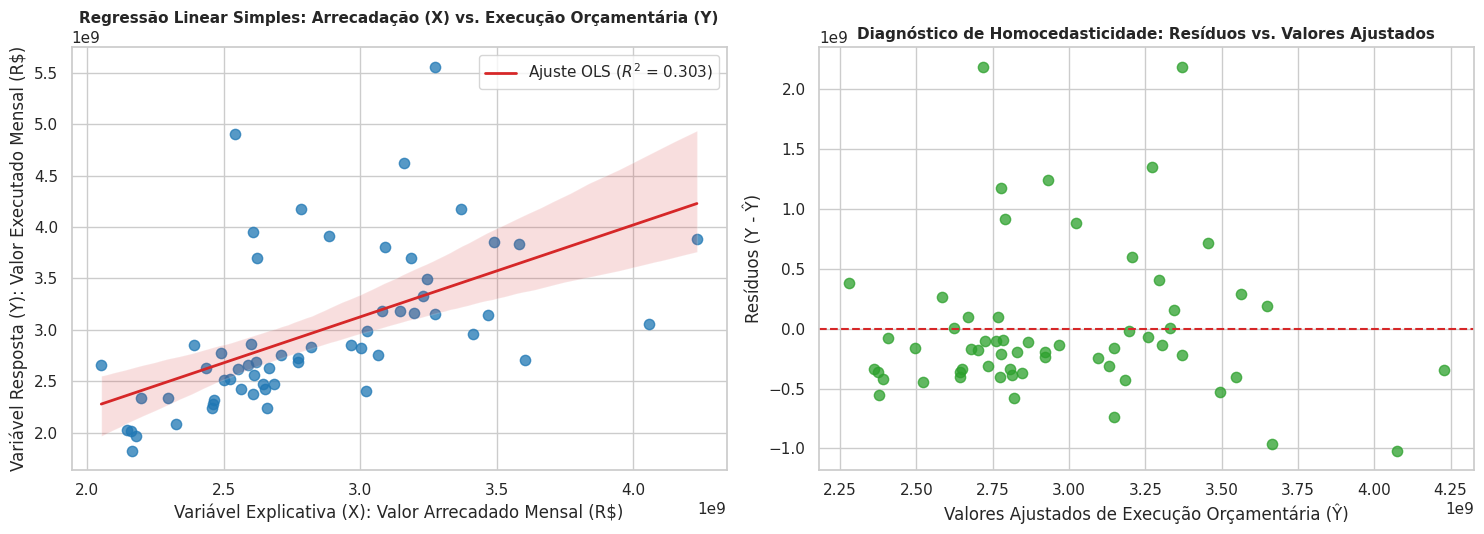

In [ ]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import statsmodels.api as sm

# 1. Leitura direta da tabela consolidada no SQLite
conn = sqlite3.connect("/content/financas_publicas.db")   #Abre a conexão com o arquivo de banco de dados
df_modelo = pd.read_sql_query(
    "SELECT * FROM tb_analise_consolidada ORDER BY ano_mes", conn    #— Busca todas as colunas (*) da tabela tb_analise_consolidada,
conn.close()                                                          #já ordenadas por ano_mes, e transforma isso na tabela df_modelo no pandas.
)

X = df_modelo["valor_arrecadado"]  # Variável explicativa: valor arrecadado mensal
Y = df_modelo[
    "valor_executado"
]  # Variável resposta: valor executado no orçamento mensal

# 2. Análise de Correlação Linear de Pearson
r, p_valor_corr = stats.pearsonr(X, Y)

print("=== ANÁLISE DE CORRELAÇÃO LINEAR (PEARSON) ===")
print(f"Observações (meses): {len(df_modelo)}")  #(Observações / meses): Mostra quantos meses/linhas entraram na conta.
print(f"Coeficiente de Correlação (r): {r:.4f}")  #Vai de -1 a +1 e mede a força e a direção da relação linear:
print(f"P-valor (Correlação):          {p_valor_corr:.4e}")

# 3. Ajuste do Modelo de Regressão Linear Simples (OLS)
X_const = sm.add_constant(X)
modelo_ols = sm.OLS(Y, X_const).fit()

beta_0 = modelo_ols.params["const"]
beta_1 = modelo_ols.params["valor_arrecadado"]
r2 = modelo_ols.rsquared
p_valor_beta1 = modelo_ols.pvalues["valor_arrecadado"]

print("\n=== EQUAÇÃO DA REGRESSÃO LINEAR SIMPLES ===")
print(f"Y_estimado = {beta_0:,.2f} + ({beta_1:.6f}) * X")
print(
    f"Coeficiente de Determinação (R²): {r2:.4f} ({r2*100:.2f}% da variância"
    " explicada)"
)
print(f"P-valor do coeficiente angular (β₁): {p_valor_beta1:.4e}\n")

print(modelo_ols.summary())

# 4. Visualização: Dispersão com Reta de Regressão e Análise de Resíduos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.regplot(
    data=df_modelo,
    x="valor_arrecadado",
    y="valor_executado",
    ax=axes[0],
    scatter_kws={"alpha": 0.75, "color": "#1f77b4", "s": 55},
    line_kws={
        "color": "#d62728",
        "linewidth": 2,
        "label": f"Ajuste OLS ($R^2$ = {r2:.3f})",
    },
)
axes[0].set_title(
    "Regressão Linear Simples: Arrecadação (X) vs. Execução Orçamentária (Y)",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Variável Explicativa (X): Valor Arrecadado Mensal (R$)")
axes[0].set_ylabel("Variável Resposta (Y): Valor Executado Mensal (R$)")
axes[0].legend()

valores_ajustados = modelo_ols.fittedvalues
residuos = modelo_ols.resid
axes[1].scatter(valores_ajustados, residuos, alpha=0.75, color="#2ca02c", s=55)
axes[1].axhline(0, color="#d62728", linestyle="--", linewidth=1.5)
axes[1].set_title(
    "Diagnóstico de Homocedasticidade: Resíduos vs. Valores Ajustados",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Valores Ajustados de Execução Orçamentária (Ŷ)")
axes[1].set_ylabel("Resíduos (Y - Ŷ)")

plt.tight_layout()
plt.show()